# Choropleth Populasi ASEAN

## 1. Persiapan

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Proj
import load_data as L
import project as P
import plot as PL
import validate as V

np.random.seed(L.SEED)
pd.options.display.float_format = "{:,.1f}".format

## 2. Data Natural Earth

In [2]:
world = L.load_countries()
print(len(world), world.crs)

242 EPSG:4326


## 3. Filter 11 Negara

In [3]:
sel = L.select_targets(world)
sel[["ADM0_A3", "ISO_A3", "NAME", "SUBREGION"]].sort_values("ADM0_A3").reset_index(drop=True)

,ADM0_A3,ISO_A3,NAME,SUBREGION
0,BRN,BRN,Brunei,South-Eastern Asia
1,IDN,IDN,Indonesia,South-Eastern Asia
2,KHM,KHM,Cambodia,South-Eastern Asia
3,LAO,LAO,Laos,South-Eastern Asia
4,MMR,MMR,Myanmar,South-Eastern Asia
5,MYS,MYS,Malaysia,South-Eastern Asia
6,PHL,PHL,Philippines,South-Eastern Asia
7,SGP,SGP,Singapore,South-Eastern Asia
8,THA,THA,Thailand,South-Eastern Asia
9,TLS,TLS,Timor-Leste,South-Eastern Asia


## 4. Populasi World Bank

In [4]:
pop = L.load_population()
pop

,iso3,pop,pop_year
0,BRN,"466,330.0",2025
1,KHM,"17,847,982.0",2025
2,IDN,"285,721,236.0",2025
3,LAO,"7,873,046.0",2025
4,MYS,"35,977,838.0",2025
5,MMR,"54,850,648.0",2025
6,PHL,"116,786,962.0",2025
7,SGP,"6,111,175.0",2025
8,THA,"71,619,863.0",2025
9,TLS,"1,418,517.0",2025


## 5. Luas Resmi World Bank

In [5]:
area = L.load_area()
area

,iso3,area_official_km2,area_year
0,BRN,"5,770.0",2024
1,KHM,"181,035.0",2024
2,IDN,"1,916,906.8",2024
3,LAO,"236,800.0",2024
4,MYS,"330,534.0",2024
5,MMR,"676,578.0",2024
6,PHL,"300,000.0",2024
7,SGP,735.6,2024
8,THA,"513,115.0",2024
9,TLS,"14,870.0",2024


## 6. Gabung Data dan Metrik

In [6]:
gdf = L.build_dataset()
gp = P.add_metrics(gdf)
cols = ["iso3", "name_id", "pop", "pop_year", "area_km2", "area_year", "area_geom_km2", "area_diff_pct", "density"]
gp[cols].sort_values("pop", ascending=False).reset_index(drop=True)

,iso3,name_id,pop,pop_year,area_km2,area_year,area_geom_km2,area_diff_pct,density
0,IDN,Indonesia,"285,721,236.0",2025,"1,916,906.8",2024,"1,863,901.5",-2.8,149.1
1,PHL,Filipina,"116,786,962.0",2025,"300,000.0",2024,"289,181.8",-3.6,389.3
2,VNM,Vietnam,"101,598,527.0",2025,"331,338.3",2024,"327,848.0",-1.1,306.6
3,THA,Thailand,"71,619,863.0",2025,"513,115.0",2024,"513,910.1",0.2,139.6
4,MMR,Myanmar,"54,850,648.0",2025,"676,578.0",2024,"660,975.3",-2.3,81.1
5,MYS,Malaysia,"35,977,838.0",2025,"330,534.0",2024,"326,202.7",-1.3,108.8
6,KHM,Kamboja,"17,847,982.0",2025,"181,035.0",2024,"180,669.8",-0.2,98.6
7,LAO,Laos,"7,873,046.0",2025,"236,800.0",2024,"228,232.3",-3.6,33.2
8,SGP,Singapura,"6,111,175.0",2025,735.6,2024,482.8,-34.4,"8,307.7"
9,TLS,Timor Leste,"1,418,517.0",2025,"14,870.0",2024,"14,958.6",0.6,95.4


## 7. Perbandingan Proyeksi

In [7]:
pts = gdf.to_crs(4326).geometry.representative_point()
corners = [(92, -11), (92, 28), (141, -11), (141, 28), (127, 5)]
lonlat = [(p.x, p.y) for p in pts] + corners
rows = []
for name, crs in [("Albers", P.ALBERS), ("LAEA", P.LAEA)]:
    pr = Proj(crs)
    ad = [pr.get_factors(lo, la).angular_distortion for lo, la in lonlat]
    rows.append({"proyeksi": name, "maks": max(ad), "rerata": np.mean(ad)})
pd.DataFrame(rows).set_index("proyeksi")

,maks,rerata
proyeksi,,
Albers,3.7,2.7
LAEA,5.1,1.7


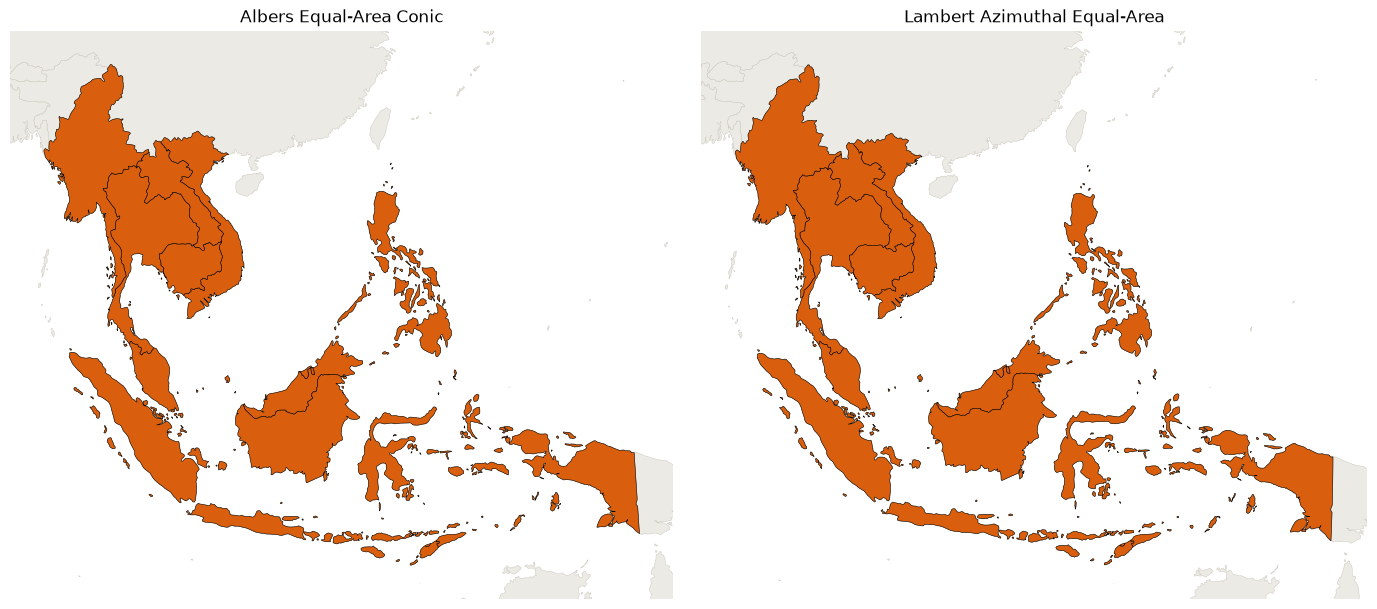

In [8]:
clip = world.clip((85, -16, 145, 32))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, crs) in zip(axes, [("Albers Equal-Area Conic", P.ALBERS), ("Lambert Azimuthal Equal-Area", P.LAEA)]):
    clip.to_crs(crs).plot(ax=ax, color="#eceae4", edgecolor="#c7c3b8", lw=0.3)
    g = gdf.to_crs(crs)
    g.plot(ax=ax, color="#d95f0e", edgecolor="k", lw=0.4)
    b = g.total_bounds
    ax.set_xlim(b[0] - 3e5, b[2] + 3e5)
    ax.set_ylim(b[1] - 3e5, b[3] + 3e5)
    ax.set_title(name)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 8. Peta Choropleth

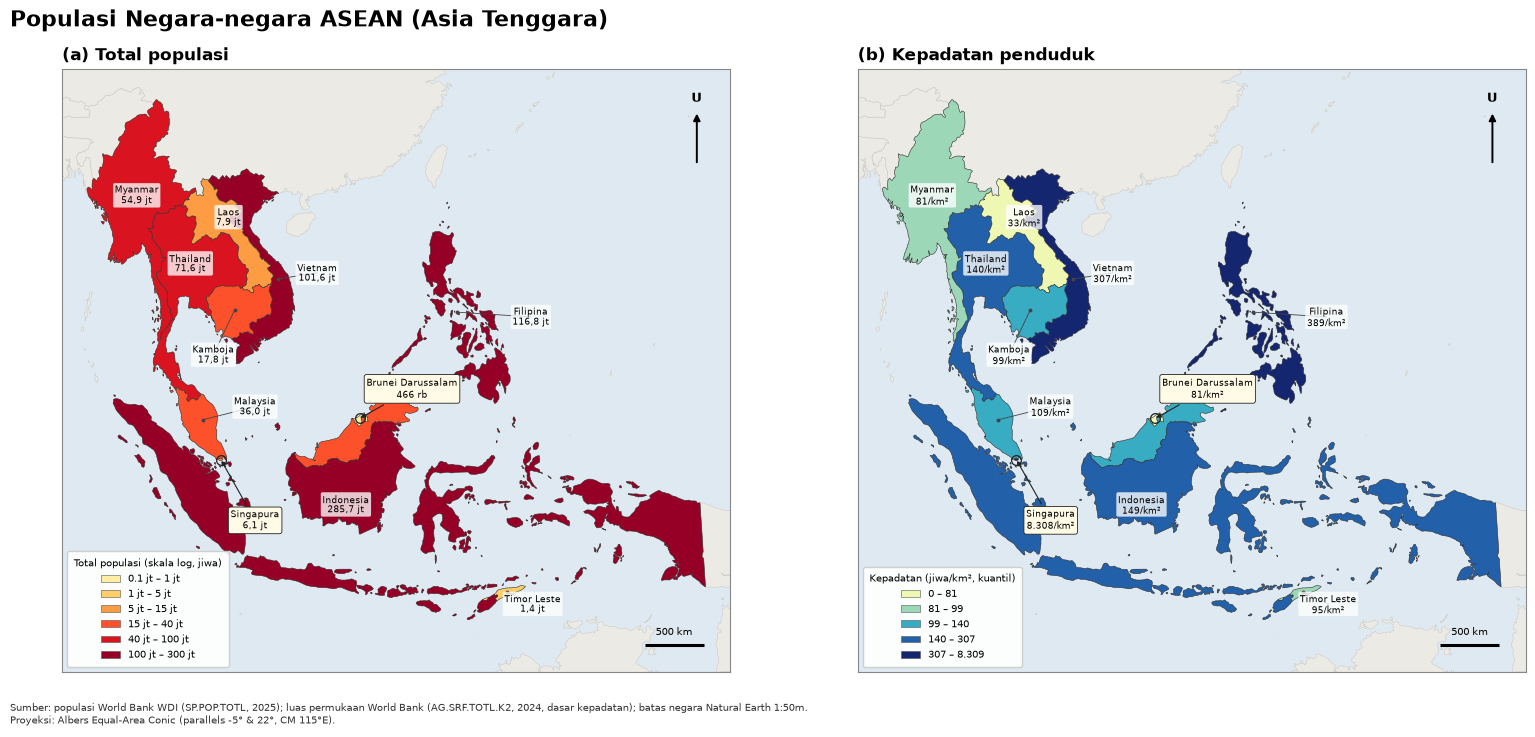

In [9]:
year = int(gp["pop_year"].max())
fig = PL.make_figure(gp, clip.to_crs(gp.crs), year)
overlaps = PL.label_overlaps(fig)
plt.show()

## 9. Ekspor dan Simpan Data

In [10]:
out = ROOT / "outputs"
fig.savefig(out / "asean_population_choropleth.png", dpi=300)
fig.savefig(out / "asean_population_choropleth.svg")
gp.to_crs(4326).to_file(L.PROCESSED / "asean_population.geojson", driver="GeoJSON")
gp.drop(columns="geometry").to_csv(L.PROCESSED / "asean_metrics.csv", index=False)
sorted(p.name for p in out.iterdir())

['asean_population_choropleth.png',
 'asean_population_choropleth.svg',
 'dashboard.html']

## 10. Validasi

In [11]:
checks = V.run_checks(gp)
res = pd.DataFrame(checks)
res["status"] = ["LOLOS" if c["ok"] else ("PERINGATAN" if c["warn"] else "GAGAL") for c in checks]
res[["name", "status", "detail"]]

,name,status,detail
0,Jumlah negara = 11,LOLOS,11 negara
1,Seluruh ISO3 target hadir,LOLOS,
2,Join populasi 11/11 (tanpa NaN),LOLOS,hilang: []
3,Geometri valid,LOLOS,
4,Luas resmi tersedia 11/11,LOLOS,hilang: []; tahun: [2024]
5,Luas resmi > 0 untuk semua negara,LOLOS,
6,Kepadatan = populasi / luas resmi,LOLOS,
7,Selisih luas geometri vs resmi <= 10% (pelaporan),PERINGATAN,"selisih (%): SGP -34.4, LAO -3.6, PHL -3.6, ID..."
8,Luas geometri Albers vs LAEA konsisten (selisi...,LOLOS,selisih maks 0.001%
9,Cek manual IDN: nilai & tahun = sumber mentah,LOLOS,"mentah 285,721,236 (2025); dataset 285,721,236..."


In [12]:
for iso in ["IDN", "SGP", "TLS"]:
    yr, val = V.raw_value(iso)
    r = gp.set_index("iso3").loc[iso]
    print(f"{iso}: mentah={val:,.0f} ({yr}) dataset={r['pop']:,.0f} kepadatan={val / r['area_km2']:,.1f} vs {r['density']:,.1f}")

IDN: mentah=285,721,236 (2025) dataset=285,721,236 kepadatan=149.1 vs 149.1
SGP: mentah=6,111,175 (2025) dataset=6,111,175 kepadatan=8,307.7 vs 8,307.7
TLS: mentah=1,418,517 (2025) dataset=1,418,517 kepadatan=95.4 vs 95.4


In [13]:
assert all(c["ok"] or c["warn"] for c in checks)
assert overlaps == []
assert gp["pop"].notna().all() and len(gp) == 11
print("Validasi selesai")

Validasi selesai
